In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from keras.layers import Dense, Flatten, Dropout

In [2]:
data = fetch_california_housing()

In [3]:
x = data.data
y = data.target

In [4]:
imputer = SimpleImputer(strategy="mean")
x = imputer.fit_transform(x)

In [5]:
xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)

In [6]:
scaler = StandardScaler()
xtrain = scaler.fit_transform(xtrain)
xtest = scaler.fit_transform(xtest)

In [7]:
model = keras.Sequential([
    Dense(100, activation="relu"),
    # Dropout(0.2),
    Dense(100, activation="relu"),
    # Dropout(0.2),
    Dense(100, activation="relu"),
    # Dropout(0.2),
    Dense(100, activation="relu"),
    # Dropout(0.2),
    Dense(100, activation="relu"),
    # Dropout(0.1),
    Dense(100, activation="relu"),
    # Dropout(0.1),
    Dense(100, activation="relu"),
    # Dropout(0.1),
    Dense(1, activation="linear")
])

In [8]:
model.compile(loss=keras.losses.MeanSquaredError(), optimizer= keras.optimizers.Adam(), metrics=["accuracy"])

In [10]:
history = model.fit(xtrain, ytrain, epochs=200, batch_size= 32)

Epoch 1/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0032 - loss: 0.2791
Epoch 2/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.0032 - loss: 0.2769
Epoch 3/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.0032 - loss: 0.2721
Epoch 4/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.0032 - loss: 0.2653
Epoch 5/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.0032 - loss: 0.2639
Epoch 6/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0032 - loss: 0.2562
Epoch 7/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.0032 - loss: 0.2540
Epoch 8/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.0032 - loss: 0.2473
Epoch 9/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.0032 - loss: 0.2458
Epoch 10/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.0032 - loss: 0.2485
Epoch 11/200
516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.0032 - loss: 0.2420
Epoch 12/200
516/516 ━━━━━━━━━━━━━━━━━━━━

In [11]:
history.history["loss"][-1::]

[0.05168227106332779]

In [13]:
score1 = model.evaluate(xtest, ytest)
score2 = model.evaluate(xtrain, ytrain)
score1, score2

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.0022 - loss: 1.3082
516/516 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0032 - loss: 0.0603


([1.3081518411636353, 0.0021802326664328575],
 [0.060292236506938934, 0.0032097867224365473])

In [15]:
i = 442
ypred = model.predict(np.array([xtest[i]]))
ypred, ytest[i]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step


(array([[4.850827]], dtype=float32), np.float64(4.272))

129/129 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


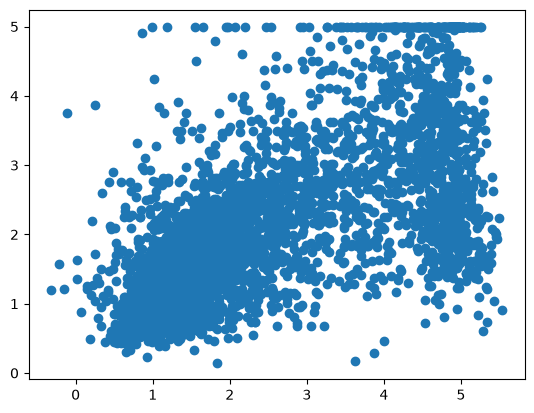

In [14]:
ypred = model.predict(xtest)
plt.scatter(ypred, ytest)
plt.show()